# Reprodução do capítulo 10: o que os ficheiros originais escondiam

O estado estacionário discreto não único dos esquemas centrados com a fração de gás livre na entrada, o «upwind» original (diferenças regressivas em todas as variáveis) e o esquema escalonado como alternativa.

Issues ilustradas (índice em [docs/issues/INDEX.md](../../docs/issues/INDEX.md)):
- [001](../../docs/issues/001-reproducao-capitulo-10.md)
- [002](../../docs/issues/002-fv-upwind.md)

*Nenhuma simulação corre aqui: as corridas vêm de `notebooks/data` (dados históricos, 2026-10)
e dos lotes `batches/*.json` (`mfsim batch`); o notebook só lê e desenha.*

In [1]:
import numpy as np, matplotlib.pyplot as plt
from mfsim.runs import load_run

## Estado estacionário discreto: fração de gás livre na entrada, gradiente nulo e esquema escalonado
Corridas `runs/issues/10_1_1_steady_<formulação>_n<N>` (lote `batches/issues.json`, `tf = 0`: só o
estacionário). Com a fração de gás livre na entrada (ficheiro original) a Jacobiana tem um autovalor
nulo e o Newton converge para um perfil de fração de gás que depende da malha; com gradiente nulo
(von Neumann) na entrada, ou com o esquema escalonado, o estado é único e igual ao da tese (αG = 0.4636).

formulação                      N  αG entrada  αG saída  P entrada (bar)


fração de gás livre (original)    5      0.4621    0.4713          100.028
gradiente nulo na entrada       5      0.4636    0.4636          100.028
escalonado (fv_upwind)          5      0.4636    0.4637          100.024
fração de gás livre (original)   50      0.4636    0.4626          100.028
gradiente nulo na entrada      50      0.4637    0.4645          100.028
escalonado (fv_upwind)         50      0.4636    0.4637          100.028


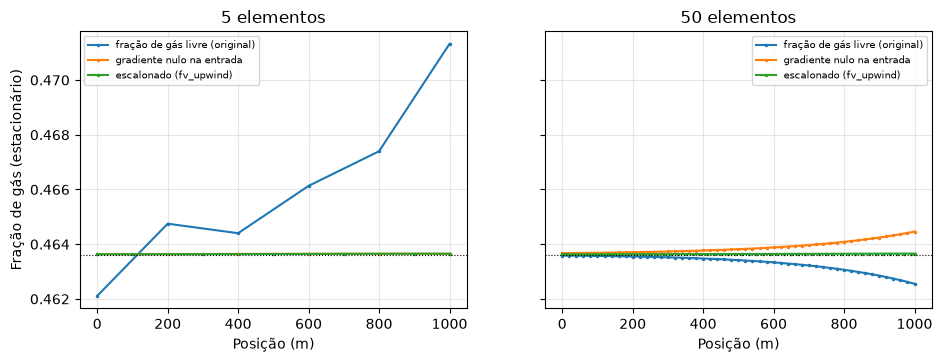

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
print(f"{'formulação':28s} {'N':>4s} {'αG entrada':>11s} {'αG saída':>9s} {'P entrada (bar)':>16s}")
for ax, n in zip(axes, (5, 50)):
    for tag, lab in (
        ("free", "fração de gás livre (original)"),
        ("neumann", "gradiente nulo na entrada"),
        ("fv", "escalonado (fv_upwind)"),
    ):
        r = load_run(f"issues/10_1_1_steady_{tag}_n{n}")
        p = r.res.pipe(0)
        aG, P = p["out"]["alphaG"][:, 0], p["out"]["P_bar"][:, 0]
        ax.plot(p["x"], aG, ".-", ms=3, label=lab)
        print(f"{lab:28s} {n:4d} {aG[0]:11.4f} {aG[-1]:9.4f} {P[0]:16.3f}")
    ax.axhline(0.4636, color="k", lw=0.8, ls=":")
    ax.set_title(f"{n} elementos")
    ax.set_xlabel("Posição (m)")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=7)
axes[0].set_ylabel("Fração de gás (estacionário)")
plt.show()

## O "upwind" original: diferenças regressivas em todas as variáveis
Corrida `runs/issues/10_1_1_fd_upwind`: o caso 10.1.1 tal e qual com o esquema `fd_upwind` da tese
(regressivas inclusive na pressão) e o BDF próprio com saída parcial. O integrador para cedo: a
pressão não tem nada de *upwind* e o esquema é instável para o modo acústico, o que explica o
insucesso relatado na tese com esse método.

sucesso = 0 | parou em t = 0.0 s de 3000 | 680 passos | RuntimeError: passo mínimo atingido em t=0.6566


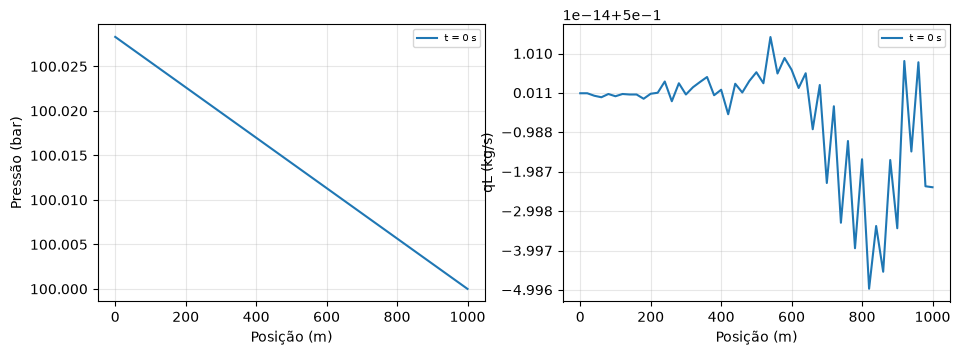

In [3]:
r = load_run("issues/10_1_1_fd_upwind")
print(
    f"sucesso = {r.info.get('success')} | parou em t = {r.T[-1]:.1f} s de 3000 | {r.info.get('n_steps')} passos | {str(r.info.get('error', ''))[:100]}"
)
p = r.res.pipe(0)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for it in range(0, r.T.size, max(1, r.T.size // 6)):
    axes[0].plot(p["x"], p["out"]["P_bar"][:, it], label=f"t = {r.T[it]:.0f} s")
    axes[1].plot(p["x"], p["out"]["qL"][:, it], label=f"t = {r.T[it]:.0f} s")
axes[0].set_ylabel("Pressão (bar)")
axes[1].set_ylabel("qL (kg/s)")
for ax in axes:
    ax.set_xlabel("Posição (m)")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=7)
plt.show()